In [2]:
from pathlib import Path

model_dir = Path("../models")

for file in model_dir.glob("candidate_*.joblib"):
    print(file.name)

candidate_gradient_boosting.joblib
candidate_logistic_regression.joblib


In [3]:
import joblib
from pathlib import Path

model_dir = Path("../models")

candidates = {}

for file in model_dir.glob("candidate_*.joblib"):
    name = file.stem.replace("candidate_", "")
    candidates[name] = joblib.load(file)

print("Loaded candidate models:")

for name in candidates:
    print(name)

Loaded candidate models:
gradient_boosting
logistic_regression


In [4]:

import sys, json
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_score,
    recall_score, f1_score, fbeta_score, confusion_matrix
)

from src.preprocess import get_train_test_split, RANDOM_STATE

sns.set_theme(style="whitegrid")

# Load dataset
X_train, X_test, y_train, y_test = get_train_test_split(
    "../data/telco_churn.csv"
)

# Cross-validation setup
cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE
)

# Load only the two existing candidate models
model_dir = Path("../models")
candidates = {}

for file in model_dir.glob("candidate_*.joblib"):
    name = file.stem.replace("candidate_", "")
    candidates[name] = joblib.load(file)

print("Loaded candidate models:", list(candidates.keys()))
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Loaded candidate models: ['gradient_boosting', 'logistic_regression']
Training data: (5634, 20)
Testing data: (1409, 20)


In [6]:

def oof_proba(pipe, X, y, name):
    """Out-of-fold churn probabilities: each row is scored by a model that never saw it."""
    oof = np.zeros(len(y))

    for tr_idx, va_idx in cv.split(X, y):
        p = clone(pipe)
        Xtr, ytr = X.iloc[tr_idx], y.iloc[tr_idx]

        if name == "gradient_boosting":
            p.fit(
                Xtr, ytr,
                model__sample_weight=compute_sample_weight("balanced", ytr)
            )
        else:
            p.fit(Xtr, ytr)

        oof[va_idx] = p.predict_proba(X.iloc[va_idx])[:, 1]

    return oof


oof = {
    name: oof_proba(pipe, X_train, y_train, name)
    for name, pipe in candidates.items()
}

summary = pd.DataFrame({
    name: {
        "OOF ROC-AUC": roc_auc_score(y_train, p),
        "OOF PR-AUC": average_precision_score(y_train, p)
    }
    for name, p in oof.items()
}).T.round(4)

summary


,OOF ROC-AUC,OOF PR-AUC
gradient_boosting,0.8487,0.6614
logistic_regression,0.8483,0.6663


In [7]:
final_name = summary["OOF ROC-AUC"].idxmax()
print("Selected:", final_name)

Selected: gradient_boosting


In [10]:
# ASSUMPTIONS: replace with figures from the business, or state them as illustrative.
COST_MISSED_CHURNER = 500   # revenue lost when a churner is not targeted
COST_OFFER = 50             # cost of a retention offer given to a customer
SAVE_RATE = 0.30            # share of targeted churners the offer actually retains

p = oof[final_name]
rows = []
for t in np.arange(0.05, 0.96, 0.01):
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
    # Cost = offers sent + churners lost (targeted churners are saved at SAVE_RATE)
    cost = (tp + fp) * COST_OFFER + fn * COST_MISSED_CHURNER + tp * (1 - SAVE_RATE) * COST_MISSED_CHURNER
    rows.append({"threshold": round(t, 2), "cost": cost,
                 "precision": precision_score(y_train, pred, zero_division=0),
                 "recall": recall_score(y_train, pred),
                 "f1": f1_score(y_train, pred),
                 "f2": fbeta_score(y_train, pred, beta=2),
                 "flagged_%": pred.mean() * 100})
thr = pd.DataFrame(rows)

best_cost = thr.loc[thr["cost"].idxmin()]
best_f2 = thr.loc[thr["f2"].idxmax()]
print("Min-cost threshold:\n", best_cost.round(3).to_dict())
print("Max-F2 threshold:\n", best_f2.round(3).to_dict())

Min-cost threshold:
 {'threshold': 0.62, 'cost': 679200.0, 'precision': 0.592, 'recall': 0.698, 'f1': 0.64, 'f2': 0.674, 'flagged_%': 31.292}
Max-F2 threshold:
 {'threshold': 0.33, 'cost': 694850.0, 'precision': 0.451, 'recall': 0.902, 'f1': 0.601, 'f2': 0.752, 'flagged_%': 53.142}


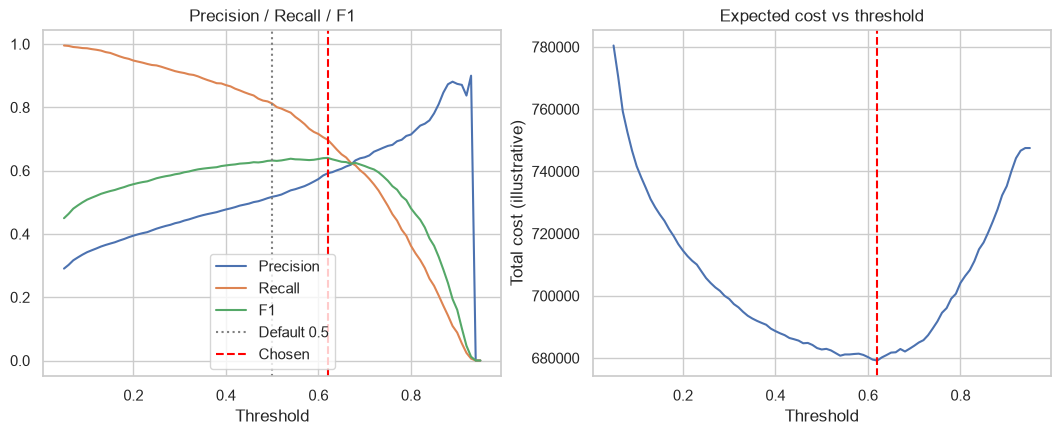

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(thr["threshold"], thr["precision"], label="Precision")
axes[0].plot(thr["threshold"], thr["recall"], label="Recall")
axes[0].plot(thr["threshold"], thr["f1"], label="F1")
axes[0].axvline(0.5, color="gray", linestyle=":", label="Default 0.5")
axes[0].axvline(best_cost["threshold"], color="red", linestyle="--", label="Chosen")
axes[0].set_xlabel("Threshold"); axes[0].legend(); axes[0].set_title("Precision / Recall / F1")

axes[1].plot(thr["threshold"], thr["cost"])
axes[1].axvline(best_cost["threshold"], color="red", linestyle="--")
axes[1].set_xlabel("Threshold"); axes[1].set_ylabel("Total cost (illustrative)")
axes[1].set_title("Expected cost vs threshold")

plt.savefig("../reports/threshold_tuning.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
THRESHOLD = round(float(best_cost["threshold"]), 2)   # or set manually after reviewing the plot
print("Final threshold:", THRESHOLD)

Final threshold: 0.62


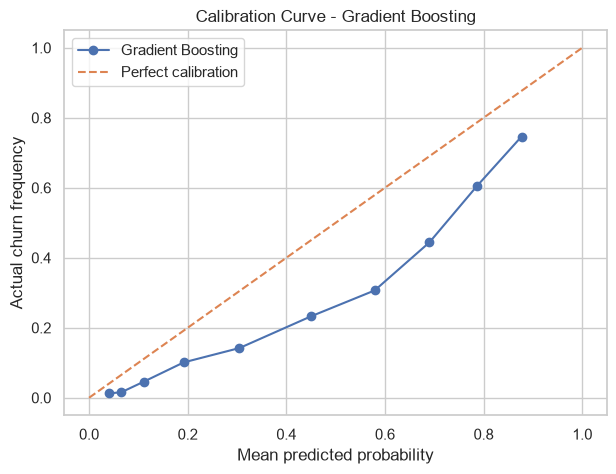

In [13]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

# Check calibration using out-of-fold predictions
gb_oof = oof["gradient_boosting"]

prob_true, prob_pred = calibration_curve(
    y_train,
    gb_oof,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 5))
plt.plot(prob_pred, prob_true, marker="o", label="Gradient Boosting")
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")

plt.xlabel("Mean predicted probability")
plt.ylabel("Actual churn frequency")
plt.title("Calibration Curve - Gradient Boosting")
plt.legend()
plt.grid(True)
plt.show()

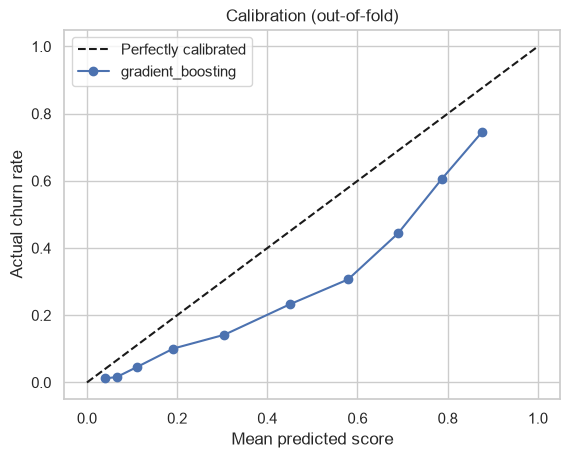

In [14]:
from sklearn.calibration import calibration_curve

frac_pos, mean_pred = calibration_curve(y_train, oof[final_name], n_bins=10, strategy="quantile")

plt.plot([0, 1], [0, 1], "k--", label="Perfectly calibrated")
plt.plot(mean_pred, frac_pos, "o-", label=final_name)
plt.xlabel("Mean predicted score"); plt.ylabel("Actual churn rate")
plt.legend(); plt.title("Calibration (out-of-fold)")
plt.savefig("../reports/calibration.png", dpi=150, bbox_inches="tight")
plt.show()

In [19]:
p = oof[final_name]
bands = pd.cut(p, bins=[0, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0], include_lowest=True)
band_table = (pd.DataFrame({"band": bands, "churn": y_train.values})
              .groupby("band", observed=True)["churn"]
              .agg(customers="count", actual_churn_rate="mean"))
band_table["actual_churn_rate"] = (band_table["actual_churn_rate"] * 100).round(1)
band_table

,customers,actual_churn_rate
band,,
"(-0.001, 0.2]",2042,3.8
"(0.2, 0.3]",476,11.6
"(0.3, 0.4]",390,15.6
"(0.4, 0.5]",379,23.0
"(0.5, 0.6]",481,29.9
"(0.6, 0.7]",494,38.3
"(0.7, 0.8]",613,55.3
"(0.8, 1.0]",759,71.4


In [18]:
# Create a dataframe using out-of-fold predictions
tier_df = pd.DataFrame({
    "risk_score": oof[final_name],
    "actual_churn": np.asarray(y_train)
})

# Divide customers into three approximately equal-sized groups
tier_df["risk_tier"] = pd.qcut(
    tier_df["risk_score"].rank(method="first"),
    q=3,
    labels=["Low", "Medium", "High"]
)

# Summarize actual churn behaviour in each tier
tier_summary = tier_df.groupby(
    "risk_tier", observed=False
).agg(
    customers=("risk_score", "size"),
    min_score=("risk_score", "min"),
    max_score=("risk_score", "max"),
    actual_churn_rate=("actual_churn", "mean")
)

tier_summary["actual_churn_rate"] *= 100

tier_summary.round(2)

,customers,min_score,max_score,actual_churn_rate
risk_tier,,,,
Low,1878,0.02,0.18,3.25
Medium,1878,0.18,0.60,19.28
High,1878,0.60,0.94,57.08


In [16]:
# Starting proposal: Low below the threshold's lower half, High above the threshold-plus zone.
# Adjust after reading band_table so each tier has clearly different actual churn rates.
LOW_MAX = round(THRESHOLD * 0.6, 2)    # example: 0.24 if THRESHOLD is 0.40
HIGH_MIN = round(max(THRESHOLD + 0.2, 0.6), 2)

def tier(score):
    return "Low" if score < LOW_MAX else ("Medium" if score < HIGH_MIN else "High")

tiers = pd.Series(p).map(tier)
check = (pd.DataFrame({"tier": tiers, "churn": y_train.values})
         .groupby("tier")["churn"].agg(customers="count", actual_churn_rate="mean")
         .reindex(["Low", "Medium", "High"]))
check["actual_churn_rate"] = (check["actual_churn_rate"] * 100).round(1)
print(f"LOW_MAX={LOW_MAX}, HIGH_MIN={HIGH_MIN}")
check

LOW_MAX=0.37, HIGH_MIN=0.82


,customers,actual_churn_rate
tier,,
Low,2804,6.3
Medium,2190,38.5
High,640,74.2


In [20]:
final_pipe = candidates[final_name]      # already fitted on the full training set in Phase 5
test_score = final_pipe.predict_proba(X_test)[:, 1]
test_pred = (test_score >= THRESHOLD).astype(int)
default_pred = (test_score >= 0.5).astype(int)

report = pd.DataFrame({
    "At 0.5": [precision_score(y_test, default_pred), recall_score(y_test, default_pred),
               f1_score(y_test, default_pred)],
    f"At {THRESHOLD}": [precision_score(y_test, test_pred), recall_score(y_test, test_pred),
                        f1_score(y_test, test_pred)],
}, index=["Precision", "Recall", "F1"]).round(3)

print("ROC-AUC:", round(roc_auc_score(y_test, test_score), 4))
print("PR-AUC: ", round(average_precision_score(y_test, test_score), 4))
print(report)
print(confusion_matrix(y_test, test_pred))

ROC-AUC: 0.8458
PR-AUC:  0.6632
           At 0.5  At 0.62
Precision   0.518    0.575
Recall      0.807    0.701
F1          0.631    0.631
[[841 194]
 [112 262]]


In [21]:
test_tiers = pd.Series(test_score).map(tier)
test_check = (pd.DataFrame({"tier": test_tiers, "churn": y_test.values})
              .groupby("tier")["churn"].agg(customers="count", actual_churn_rate="mean")
              .reindex(["Low", "Medium", "High"]))
test_check["actual_churn_rate"] = (test_check["actual_churn_rate"] * 100).round(1)
test_check

,customers,actual_churn_rate
tier,,
Low,700,6.7
Medium,559,38.1
High,150,76.0


In [22]:
import sklearn, xgboost, os

joblib.dump(final_pipe, "../models/churn_model.joblib", compress=3)

config = {
    "model_name": final_name,
    "threshold": THRESHOLD,
    "low_max": LOW_MAX,
    "high_min": HIGH_MIN,
    "score_is_calibrated": False,          # set True if you calibrated in Step 2
    "sklearn_version": sklearn.__version__,
    "xgboost_version": xgboost.__version__,
    "assumptions": {"cost_missed_churner": COST_MISSED_CHURNER,
                    "cost_offer": COST_OFFER, "save_rate": SAVE_RATE},
}
with open("../models/model_config.json", "w") as f:
    json.dump(config, f, indent=2)

print(round(os.path.getsize("../models/churn_model.joblib") / 1e6, 2), "MB")

0.08 MB


In [23]:
loaded = joblib.load("../models/churn_model.joblib")

sample = X_test.iloc[[0]]            # raw row, including customerID
print(sample.T.head(8))
print("Score:", loaded.predict_proba(sample)[0, 1].round(3))

                      437
customerID     4376-KFVRS
gender               Male
SeniorCitizen           0
Partner               Yes
Dependents            Yes
tenure                 72
PhoneService          Yes
MultipleLines         Yes
Score: 0.067
